In [1]:
# CELL 1: INSTALL/UPGRADE
# Run this cell, then RESTART your runtime/session.

!pip install --upgrade --no-cache-dir yfinance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.4/119.4 kB 6.9 MB/s eta 0:00:00
  Attempting uninstall: yfinance
    Found existing installation: yfinance 0.2.63
    Uninstalling yfinance-0.2.63:
      Successfully uninstalled yfinance-0.2.63


In [2]:
# ===================================================================
# SETUP AND PART 1: DATA PREPARATION
# ===================================================================
# Use -q for a quieter installation
!pip install -q --upgrade --no-cache-dir yfinance
import yfinance as yf; print(f"yfinance version: {yf.__version__}")
import pandas as pd
import numpy as np
import tensorflow as tf; print(f"TensorFlow version: {tf.__version__}")
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import time

# Let's confirm TensorFlow can see the GPU
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"\n✅ GPU found and enabled: {gpu_devices[0]}")
else:
    print("\n⚠️ No GPU found. Running on CPU.")

np.random.seed(42)
tf.random.set_seed(42)

# Download, clean, and preprocess data
ticker = "CL=F"
data = yf.download(ticker, start="2010-01-01", auto_adjust=False, progress=False)
df = data[['Close']].copy()
df.fillna(method='ffill', inplace=True)
indices_to_remove = np.random.choice(df.index, int(0.10 * len(df)), replace=False)
df.loc[indices_to_remove, 'Close'] = np.nan
df.interpolate(method='linear', inplace=True)

# Split, scale, and create sequences
price_data = df['Close'].values.reshape(-1, 1)
split_index = int(len(price_data) * 0.7)
train_data, test_data = price_data[:split_index], price_data[split_index:]
scaler = MinMaxScaler(feature_range=(0, 1))
train_data_scaled = scaler.fit_transform(train_data)
test_data_scaled = scaler.transform(test_data)

def create_sequences(data, lookback):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:(i + lookback), 0])
        y.append(data[i + lookback, 0])
    return np.array(X), np.array(y)

lookback_period = 60
X_train, y_train = create_sequences(train_data_scaled, lookback_period)
X_test, y_test = create_sequences(test_data_scaled, lookback_period)
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print(f"\nData prepared. X_train shape: {X_train.shape}")

yfinance version: 0.2.65


2025-07-11 16:30:06.367750: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1752251406.576936      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1752251406.644901      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow version: 2.18.0

✅ GPU found and enabled: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Data prepared. X_train shape: (2672, 60, 1)


/tmp/ipykernel_19/3471523005.py:31: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)


I0000 00:00:1752251421.986053      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0




==================== Training LSTM Model ====================


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 60, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 60, 512)        │     1,052,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 512)            │     2,099,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │        12,825 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,164,723 (12.07 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 60, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 60, 1024)       │     2,105,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 1024)           │     6,295,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 25)             │        25,625 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,426,547 (32.14 MB)

 Trainable params: 8,426,547 (32.14 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 119ms/step - loss: 0.3447 - val_loss: 0.0046
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - loss: 0.0037 - val_loss: 0.0038
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 0.0014 - val_loss: 0.0030
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - loss: 0.0011 - val_loss: 0.0024
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - loss: 7.7977e-04 - val_loss: 0.0020
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - loss: 7.1891e-04 - val_loss: 0.0017
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 5.8741e-04 - val_loss: 0.0014
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 4.7555e-04 - val_loss: 0.0013
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - loss: 4.1303e-04 - val_loss: 0.0012
Epoch 10/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - loss: 3.8920e-04 - val_loss: 0.0011
Epoch 11/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 5.2090e-04 - val_loss: 0.0010
Epoch 12/50
25/25 ━━━━━━━━━━━━━━━━

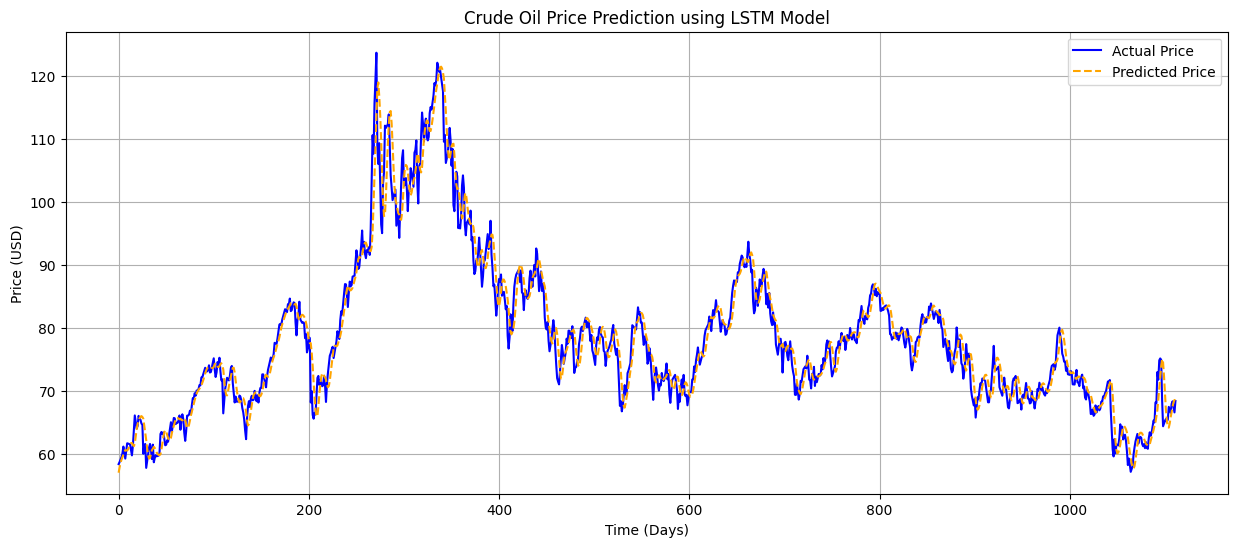


Evaluating GRU model...
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


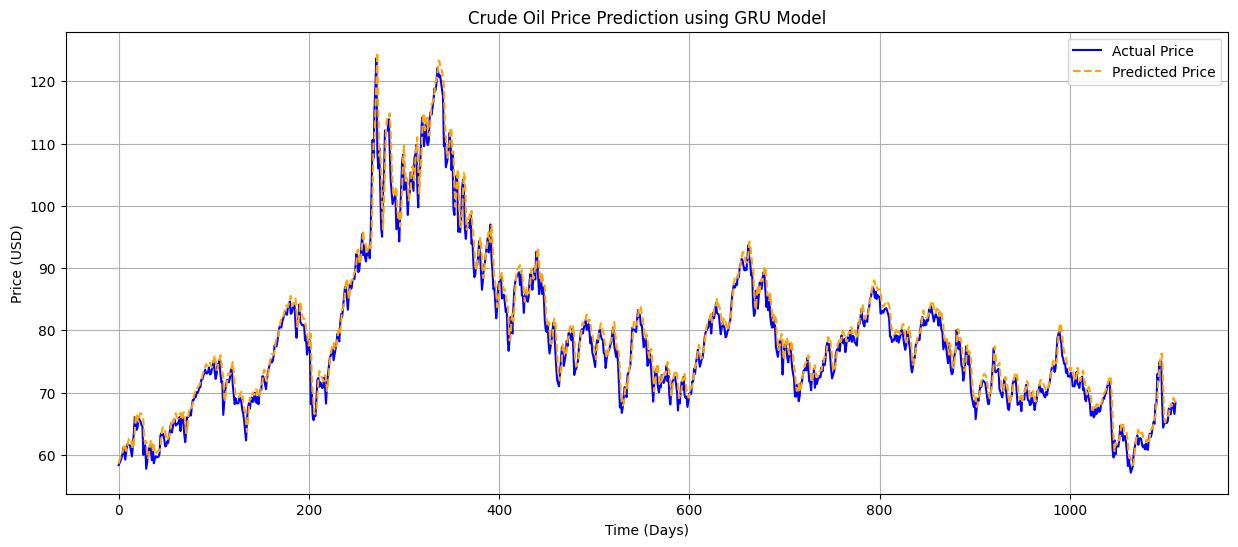


Evaluating Bi-LSTM model...
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step


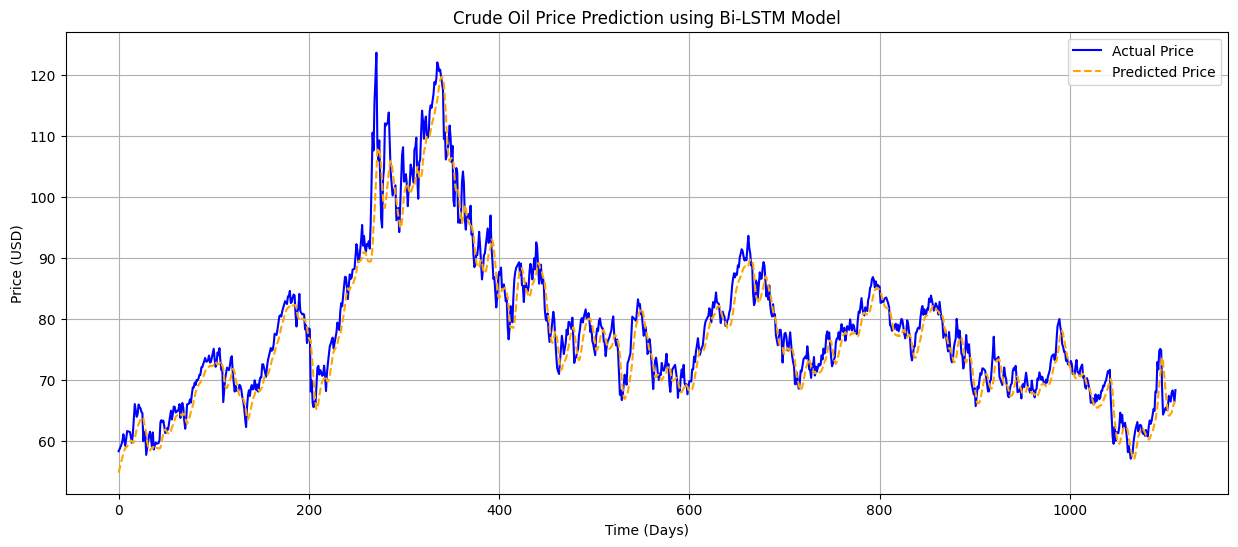



           MODEL PERFORMANCE COMPARISON
            MAE    RMSE  R-Squared  MAPE (%)
LSTM     2.0551  2.8662     0.9451    2.5880
GRU      1.6625  2.2971     0.9648    2.1136
Bi-LSTM  2.2999  3.0779     0.9367    2.8861

Analysis:
The model with the lowest MAPE is 'GRU' with a MAPE of 2.1136%.

This completes the assignment requirements. You now have the metrics table and plots for your report.


In [3]:
# ===================================================================
# PART 2: MODEL IMPLEMENTATION AND TRAINING (GPU)
# ===================================================================

# --- Hyperparameters ---
LEARNING_RATE = 0.001
LOSS_FUNCTION = 'mean_squared_error'
BATCH_SIZE = 100 # Correct batch size for a single GPU
EPOCHS = 50
input_shape = (lookback_period, 1)

# --- Model Building Function (Functional API) ---
def build_model(model_type, input_shape):
    inputs = keras.Input(shape=input_shape)
    if model_type == 'LSTM':
        x = layers.LSTM(512, return_sequences=True)(inputs)
        x = layers.LSTM(512, return_sequences=False)(x)
    elif model_type == 'GRU':
        x = layers.GRU(512, return_sequences=True)(inputs)
        x = layers.GRU(512, return_sequences=False)(x)
    elif model_type == 'Bi-LSTM':
        x = layers.Bidirectional(layers.LSTM(512, return_sequences=True))(inputs)
        x = layers.Bidirectional(layers.LSTM(512, return_sequences=False))(x)
    x = layers.Dense(25, activation='relu')(x)
    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss=LOSS_FUNCTION)
    return model

# --- Build the Models ---
lstm_model = build_model('LSTM', input_shape)
gru_model = build_model('GRU', input_shape)
bilstm_model = build_model('Bi-LSTM', input_shape)

# --- Train the Models ---
models = {"LSTM": lstm_model, "GRU": gru_model, "Bi-LSTM": bilstm_model}
histories = {}
training_times = {}

for name, model in models.items():
    print(f"\n\n{'='*20} Training {name} Model {'='*20}")
    model.summary()
    start_time = time.time()
    history = model.fit(
        X_train,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.1,
        verbose=1
    )
    training_times[name] = time.time() - start_time
    print(f"{'-'*20} {name} Model Trained in {training_times[name]:.2f} seconds {'-'*20}")
    model.save(f'{name.lower().replace("-", "_")}_model.keras')

# ===================================================================
# PART 3: EVALUATION AND ANALYSIS
# ===================================================================
print("\n\n--- Starting Evaluation ---")
results = {}

def calculate_mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    y_true = np.where(y_true == 0, 1e-18, y_true)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

for name, model in models.items():
    print(f"\nEvaluating {name} model...")
    predictions_scaled = model.predict(X_test)
    predictions = scaler.inverse_transform(predictions_scaled)
    y_test_unscaled = scaler.inverse_transform(y_test.reshape(-1, 1))
    
    mae = mean_absolute_error(y_test_unscaled, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_unscaled, predictions))
    r2 = r2_score(y_test_unscaled, predictions)
    mape = calculate_mape(y_test_unscaled, predictions)
    results[name] = {'MAE': mae, 'RMSE': rmse, 'R-Squared': r2, 'MAPE (%)': mape}

    # Plotting
    plt.figure(figsize=(15, 6))
    plt.plot(y_test_unscaled, color='blue', label='Actual Price')
    plt.plot(predictions, color='orange', linestyle='--', label='Predicted Price')
    plt.title(f'Crude Oil Price Prediction using {name} Model')
    plt.xlabel('Time (Days)')
    plt.ylabel('Price (USD)')
    plt.legend()
    plt.grid(True)
    plt.show()

# Final Results Table
results_df = pd.DataFrame(results).T
print("\n\n" + "="*50)
print("           MODEL PERFORMANCE COMPARISON")
print("="*50)
print(results_df.round(4))

# Analysis
best_model_name = results_df['MAPE (%)'].idxmin()
print(f"\nAnalysis:\nThe model with the lowest MAPE is '{best_model_name}' with a MAPE of {results_df.loc[best_model_name, 'MAPE (%)']:.4f}%.")
print("\nThis completes the assignment requirements. You now have the metrics table and plots for your report.")